In [7]:
import random, time
from dataclasses import dataclass, field
from pathlib import Path

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [8]:
# CONFIGURACIÓN
CARPETA = r"./dataset_manzanas"
SUBCARPETA_IMAGENES = "imagenes"
SUBCARPETA_MASCARAS = "mascaras"
SEMILLA = 42
FRAC_AJUSTE = 0.7 # 70 % ajuste de parámetros / 30 % test final

In [9]:
# Lista de nombres de archivo (las máscaras se llaman igual que las imágenes)
nombres = sorted(os.listdir(os.path.join(CARPETA, SUBCARPETA_IMAGENES)))

# División ajuste / test, reproducible gracias a la semilla
random.seed(SEMILLA)
random.shuffle(nombres)
corte = int(len(nombres) * FRAC_AJUSTE)
ajuste = nombres[:corte]
test = nombres[corte:]

def cargar_par(nombre):
    """Devuelve la imagen (BGR) y su máscara binaria (0/1)."""
    img = cv.imread(os.path.join(CARPETA, SUBCARPETA_IMAGENES, nombre))
    mascara = cv.imread(os.path.join(CARPETA, SUBCARPETA_MASCARAS, nombre), cv.IMREAD_GRAYSCALE)
    return img, (mascara > 127).astype(np.uint8)

print(len(nombres), "imágenes |", len(ajuste), "ajuste |", len(test), "test")

100 imágenes | 70 ajuste | 30 test


In [ ]:
# Funcion auxiliar para evitar divisiones por cero
def _div(a, b):
    return a / b if b > 0 else 0.0

def metricas_pixel(pred, gt):
    p = pred > 0
    g = gt > 0
    TP = int(np.sum(p & g))      # manzana detectada como manzana
    TN = int(np.sum(~p & ~g))    # fondo detectado como fondo
    FP = int(np.sum(p & ~g))     # fondo marcado como manzana
    FN = int(np.sum(~p & g))     # manzana que se nos escapa
    return {"TP": TP, "TN": TN, "FP": FP, "FN": FN,
            "exactitud": _div(TP + TN, p.size),
            "precision": _div(TP, TP + FP),
            "recall": _div(TP, TP + FN),
            "iou": _div(TP, TP + FP + FN),
            "dice": _div(2 * TP, 2 * TP + FP + FN)}

def metricas_objeto(pred, gt, iou_min=0.5, area_min=30):
    """Cuenta manzanas. iou_min = fracción mínima de solape para dar por buena una detección."""
    p = (pred > 0).astype(np.uint8)
    g = (gt > 0).astype(np.uint8)
    n_p, lab_p = cv.connectedComponents(p)     # la etiqueta 0 es el fondo
    n_g, lab_g = cv.connectedComponents(g)

    # Manzanas reales: está detectada si la predicción cubre al menos iou_min de su área
    n_gt, detectadas = 0, 0
    for i in range(1, n_g):
        region = lab_g == i
        if region.sum() < area_min:
            continue
        n_gt += 1
        if p[region].mean() >= iou_min:
            detectadas += 1

    # Objetos predichos: es falso positivo si cae mayormente sobre fondo
    n_pred, falsos = 0, 0
    for i in range(1, n_p):
        region = lab_p == i
        if region.sum() < area_min:
            continue
        n_pred += 1
        if g[region].mean() < iou_min:
            falsos += 1

    precision = _div(n_pred - falsos, n_pred)
    recall = _div(detectadas, n_gt)
    return {"n_gt": n_gt, "n_pred": n_pred,
            "obj_TP": detectadas, "obj_FP": falsos, "obj_FN": n_gt - detectadas,
            "obj_precision": precision, "obj_recall": recall,
            "obj_f1": _div(2 * precision * recall, precision + recall),
            "error_conteo": n_pred - n_gt}

In [11]:
# ---------- Preprocesado: reciben una imagen y devuelven una imagen ----------
def mediana(img, k=5):
    return cv.medianBlur(img, k)                  # k debe ser impar

def gauss(img, k=5, sigma=1.5):
    return cv.GaussianBlur(img, (k, k), sigma)    # k debe ser impar

def clahe_l(img, clip=2.0, tile=8):
    """CLAHE sobre la luminosidad (canal L de Lab): corrige luz desigual."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    clahe = cv.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv.cvtColor(lab, cv.COLOR_LAB2BGR)

# ---------- Segmentación: recibe una imagen y devuelve una máscara ----------
def umbral_hsv(img, h=(22, 40), s=(70, 255), v=(90, 255)):
    """Método base: rango de color en HSV (valores de partida, SIN ajustar)."""
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    return cv.inRange(hsv, (h[0], s[0], v[0]), (h[1], s[1], v[1]))

# ---------- Postprocesado: reciben máscara (y la imagen) y devuelven máscara ----------
def abrir_cerrar(mascara, img, k_abrir=3, k_cerrar=5):
    m = (mascara > 0).astype(np.uint8) * 255
    k1 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_abrir, k_abrir))
    k2 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_cerrar, k_cerrar))
    m = cv.morphologyEx(m, cv.MORPH_OPEN, k1)      # quita motas pequeñas
    m = cv.morphologyEx(m, cv.MORPH_CLOSE, k2)     # rellena huecos
    return m

def filtrar_area(mascara, img, area_min=40, area_max=None):
    m = (mascara > 0).astype(np.uint8)
    n, etiquetas, stats, _ = cv.connectedComponentsWithStats(m, connectivity=8)
    salida = np.zeros_like(m)
    for i in range(1, n):                          # la etiqueta 0 es el fondo
        area = stats[i, cv.CC_STAT_AREA]
        if area >= area_min and (area_max is None or area <= area_max):
            salida[etiquetas == i] = 255
    return salida

# Diccionario para llamar a cada función por su nombre
CATALOGO = {"mediana": mediana, "gauss": gauss, "clahe_l": clahe_l,
            "umbral_hsv": umbral_hsv,
            "abrir_cerrar": abrir_cerrar, "filtrar_area": filtrar_area}

class Metodo:
    """Un método = preprocesados -> segmentador -> postprocesados.
    Cada etapa se escribe como (nombre, {parámetros}). Se usa como una función: metodo(img) -> máscara."""
    def __init__(self, nombre, seg, preproc=None, post=None):
        self.nombre = nombre
        self.seg = seg
        self.preproc = preproc or []
        self.post = post or []

    def __call__(self, img):
        x = img
        for nombre, params in self.preproc:
            x = CATALOGO[nombre](x, **params)
        nombre, params = self.seg
        mascara = CATALOGO[nombre](x, **params)
        for nombre, params in self.post:
            mascara = CATALOGO[nombre](mascara, img, **params)
        return (mascara > 0).astype(np.uint8)

print("Componentes disponibles:", list(CATALOGO))

Componentes disponibles: ['mediana', 'gauss', 'clahe_l', 'umbral_hsv', 'abrir_cerrar', 'filtrar_area']


In [14]:
def evaluar(metodo, nombres):
    """Aplica un método a cada imagen y devuelve una tabla (una fila por imagen)."""
    filas = []
    for nombre in nombres:
        img, gt = cargar_par(nombre)
        pred = metodo(img)
        fila = {"metodo": metodo.nombre, "id": nombre}
        fila.update(metricas_pixel(pred, gt))
        fila.update(metricas_objeto(pred, gt))
        fila["error_abs"] = abs(fila["error_conteo"])    # error de conteo sin signo
        filas.append(fila)
    return pd.DataFrame(filas)

def comparar(metodos, nombres):
    """Evalúa varios métodos y junta los resultados en una sola tabla."""
    tablas = [evaluar(m, nombres) for m in metodos]
    return pd.concat(tablas, ignore_index=True)

def resumen(tabla):
    """Media por método, ordenada de mejor a peor Dice."""
    columnas = ["iou", "dice", "precision", "recall", "obj_f1", "error_conteo", "error_abs"]
    return tabla.groupby("metodo")[columnas].mean().sort_values("dice", ascending=False)

def mostrar(img, pred, gt, titulo=""):
    # Mapa de errores: verde = acierto, rojo = falso positivo, azul = manzana perdida
    errores = np.zeros((*gt.shape, 3), dtype=np.uint8)
    errores[(pred > 0) & (gt > 0)] = (0, 255, 0)
    errores[(pred > 0) & (gt == 0)] = (255, 0, 0)
    errores[(pred == 0) & (gt > 0)] = (0, 0, 255)

    fig, ax = plt.subplots(1, 3, figsize=(14, 8))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); ax[0].set_title("Original")
    ax[1].imshow(gt, cmap="gray"); ax[1].set_title("Máscara real")
    ax[2].imshow(errores); ax[2].set_title("Verde=acierto  Rojo=falso+  Azul=perdida")
    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)
    plt.show()

# --- Prueba con el método base ---
m_base = Metodo("HSV base", seg=("umbral_hsv", {}))
tabla = comparar([m_base], ajuste[:3])
print(resumen(tabla).round(3).to_string())

            iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                    
HSV base  0.142  0.234      0.151   0.583    0.14       143.333    143.333


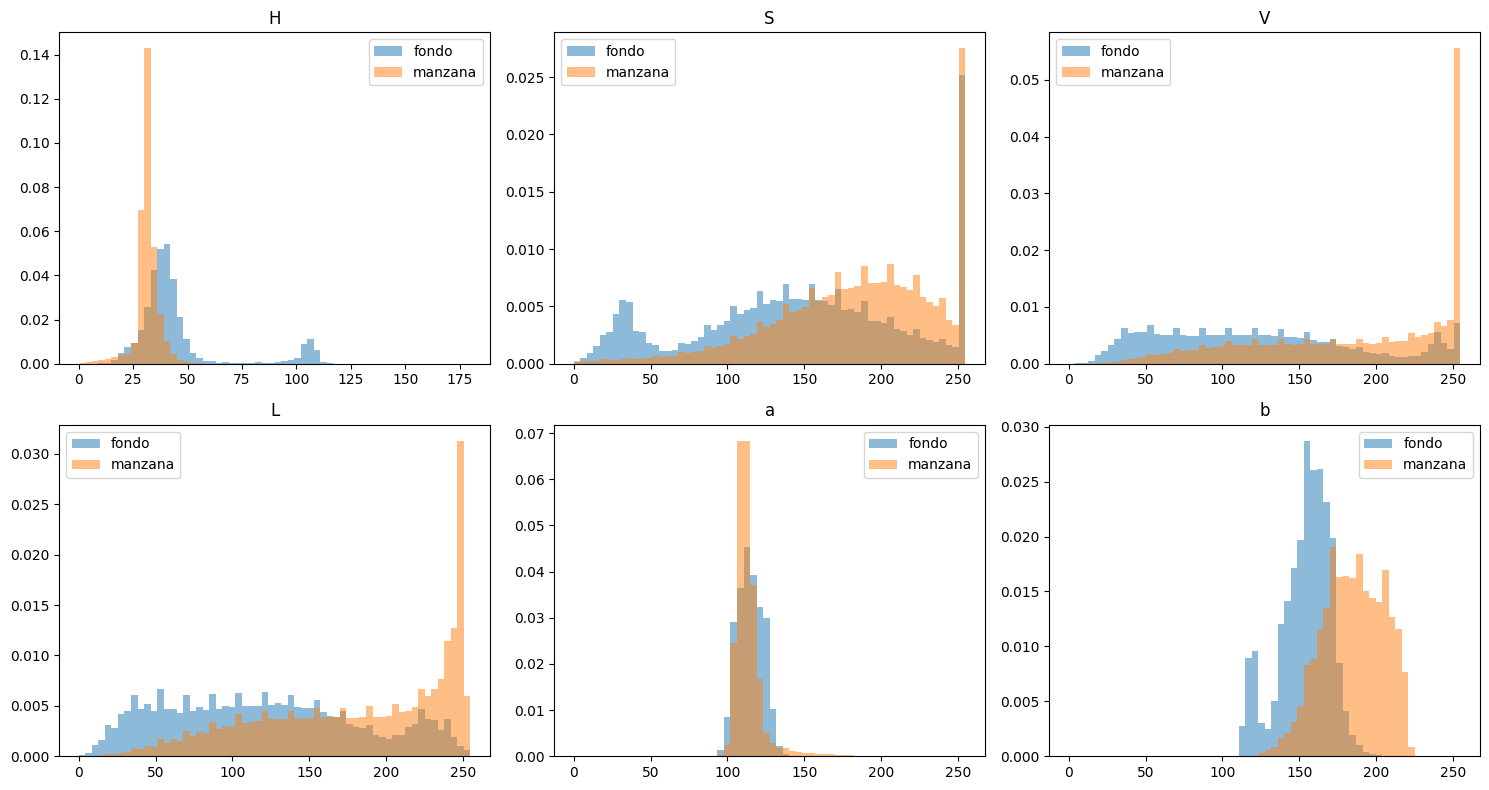

H: manzana   31.1 ±   7.2 | fondo   44.7 ±  21.9
S: manzana  183.5 ±  52.7 | fondo  146.8 ±  68.3
V: manzana  185.3 ±  64.6 | fondo  122.5 ±  64.6
L: manzana  180.3 ±  61.5 | fondo  120.2 ±  63.0
a: manzana  113.5 ±   9.4 | fondo  114.8 ±   8.2
b: manzana  184.8 ±  19.9 | fondo  153.8 ±  16.7


In [15]:
manzana = []   # cada fila: [H, S, V, L, a, b] de un píxel de manzana
fondo = []     # lo mismo para píxeles de fondo

for nombre in ajuste:
    img, gt = cargar_par(nombre)
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    pixeles = np.dstack([hsv, lab]).reshape(-1, 6)
    etiqueta = gt.reshape(-1)
    manzana.append(pixeles[etiqueta == 1][::5])    # 1 de cada 5 píxeles
    fondo.append(pixeles[etiqueta == 0][::50])     # 1 de cada 50 (hay muchos más)

manzana = np.vstack(manzana)
fondo = np.vstack(fondo)

canales = ["H", "S", "V", "L", "a", "b"]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i, c in enumerate(canales):
    rango = (0, 180) if c == "H" else (0, 255)    # en OpenCV, H va de 0 a 180
    ax[i].hist(fondo[:, i], bins=60, range=rango, density=True, alpha=0.5, label="fondo")
    ax[i].hist(manzana[:, i], bins=60, range=rango, density=True, alpha=0.5, label="manzana")
    ax[i].set_title(c)
    ax[i].legend()
plt.tight_layout()
plt.show()

for i, c in enumerate(canales):
    print(f"{c}: manzana {manzana[:, i].mean():6.1f} ± {manzana[:, i].std():5.1f} | "
          f"fondo {fondo[:, i].mean():6.1f} ± {fondo[:, i].std():5.1f}")

In [16]:
# Cada píxel de manzana muestreado representa 5 reales, y cada píxel de fondo, 50
peso_manzana = 5
peso_fondo = 50

for i, c in enumerate(canales):
    # Cuántos píxeles hay con cada valor (0-255), ya ponderados
    hist_m = np.bincount(manzana[:, i], minlength=256) * peso_manzana
    hist_f = np.bincount(fondo[:, i], minlength=256) * peso_fondo
    # Sumas acumuladas: permiten contar píxeles en un rango [lo, hi] de golpe
    acum_m = np.concatenate([[0], np.cumsum(hist_m)])
    acum_f = np.concatenate([[0], np.cumsum(hist_f)])
    total_m = acum_m[-1]

    mejor_dice, mejor_rango = 0, None
    for lo in range(256):
        for hi in range(lo, 256):
            TP = acum_m[hi + 1] - acum_m[lo]      # manzana dentro del rango
            FP = acum_f[hi + 1] - acum_f[lo]      # fondo dentro del rango
            FN = total_m - TP                     # manzana fuera del rango
            dice = 2 * TP / (2 * TP + FP + FN)
            if dice > mejor_dice:
                mejor_dice, mejor_rango = dice, (lo, hi)

    print(f"{c}: mejor rango {mejor_rango}  ->  Dice = {mejor_dice:.3f}")

H: mejor rango (29, 31)  ->  Dice = 0.326
S: mejor rango (192, 254)  ->  Dice = 0.156
V: mejor rango (248, 255)  ->  Dice = 0.253
L: mejor rango (241, 253)  ->  Dice = 0.287
a: mejor rango (107, 112)  ->  Dice = 0.133
b: mejor rango (185, 223)  ->  Dice = 0.581
